# Task 4.5


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
import time

threadpool_limits(limits=1)
FAST = True


In [2]:
def leg(x, q):
    x = np.asarray(x, dtype=float)
    z = np.zeros(x.shape + (q + 1,))
    z[..., 0] = 1
    if q > 0:
        z[..., 1] = x
    for k in range(2, q + 1):
        z[..., k] = ((2*k - 1)*x*z[..., k-1] - (k-1)*z[..., k-2]) / k
    return z


def gen(n, q, v, r, rng):
    a = rng.normal(size=(r, q + 1))
    s = np.sqrt(np.sum(a**2 / (2*np.arange(q + 1) + 1), axis=1))
    a = a / s[:, None]
    x = rng.uniform(-1, 1, size=(r, n))
    y = np.sum(leg(x, q) * a[:, None, :], axis=2)
    y = y + np.sqrt(v) * rng.normal(size=(r, n))
    return x, y, a


def eout(a, w, v=0):
    p = max(a.shape[-1], w.shape[-1])
    aa = np.zeros(a.shape[:-1] + (p,))
    ww = np.zeros(w.shape[:-1] + (p,))
    aa[..., :a.shape[-1]] = a
    ww[..., :w.shape[-1]] = w
    return v + np.sum((ww - aa)**2 / (2*np.arange(p) + 1), axis=-1)


def stat(x, axis=0):
    x = np.asarray(x)
    return x.mean(axis=axis), x.std(axis=axis, ddof=1) / np.sqrt(x.shape[axis])


def ridge(z, y, ls):
    ls = np.asarray(ls, dtype=float)
    u, s, vt = np.linalg.svd(z, full_matrices=False)
    d = s[None, :]**2 + ls[:, None]
    t = np.divide(s[None, :], d, out=np.zeros_like(d), where=d > 0)
    eps = np.finfo(float).eps * max(z.shape) * s[0]
    t[(ls[:, None] == 0) & (s[None, :] <= eps)] = 0
    w = (t * (u.T @ y)) @ vt
    h = (t * s) @ (u**2).T
    return w, h


def folds(n, k, rng):
    fs = np.array_split(rng.permutation(n), k)
    out = []
    for i in range(k):
        tr = np.concatenate([fs[j] for j in range(k) if j != i])
        out.append((tr, fs[i]))
    return out


def val(z, y, tr, va, ls):
    w, _ = ridge(z[tr], y[tr], ls)
    return np.mean((z[va] @ w.T - y[va, None])**2, axis=0)


def cv(z, y, fs, ls):
    s = np.zeros(len(ls))
    for tr, va in fs:
        s += len(va) * val(z, y, tr, va, ls)
    return s / len(y)


def loo(z, y, ls):
    w, h = ridge(z, y, ls)
    assert np.all(1 - h > 1e-12)
    r = (z @ w.T).T - y
    return np.mean((r / (1 - h))**2, axis=1)


def loo_slow(z, y, ls):
    s = np.zeros(len(ls))
    idx = np.arange(len(y))
    for i in idx:
        w, _ = ridge(z[idx != i], y[idx != i], ls)
        s += (w @ z[i] - y[i])**2
    return s / len(y)


In [3]:
rng = np.random.default_rng(407)
ls = np.r_[0, np.logspace(-4, 2, 31)]
z0 = leg(np.linspace(-1, 1, 40), 10)
y0 = rng.normal(size=40)
fast = loo(z0, y0, ls)
brute = loo_slow(z0, y0, ls)
d = np.max(np.abs(fast - brute))
print("Maximum absolute LOOCV difference:", d)
assert d < 1e-10


Maximum absolute LOOCV difference: 2.842170943040401e-14


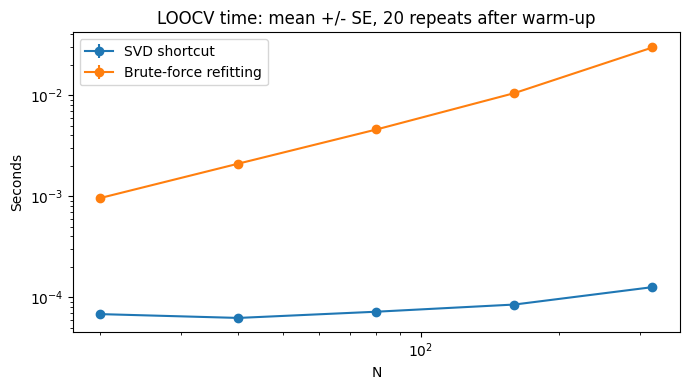

In [4]:
ns = np.array([20, 40, 80, 160, 320])
T = 20
tm = np.empty((len(ns), T, 2))
for i, n in enumerate(ns):

    z = leg(np.linspace(-1, 1, n), 10)
    y0 = np.sin(3 * z[:, 1])
    loo(z, y0, [0.1])
    loo_slow(z, y0, [0.1])
    for r in range(T):
        t0 = time.perf_counter()
        loo(z, y0, [0.1])
        tm[i, r, 0] = time.perf_counter() - t0
        t0 = time.perf_counter()
        loo_slow(z, y0, [0.1])
        tm[i, r, 1] = time.perf_counter() - t0
mt, st = stat(tm, axis=1)
fig, ax = plt.subplots(figsize=(7, 4))
for j, lab in enumerate(["SVD shortcut", "Brute-force refitting"]):
    ax.errorbar(ns, mt[:, j], yerr=st[:, j], marker="o", label=lab)
ax.set(xscale="log", yscale="log", xlabel="N", ylabel="Seconds",
       title=f"LOOCV time: mean +/- SE, {T} repeats after warm-up")
ax.legend()
fig.tight_layout()
plt.show()


In [5]:
R = 200 if FAST else 500
ks = [5, 10, 15, 20, 25]
lbl = [f"Validation {k}" for k in ks] + ["5-fold", "10-fold", "LOOCV"]
eo = np.empty((R, len(lbl)))
ev = np.empty_like(eo)
sel = np.empty_like(eo)
pre = np.empty((R, len(ks)))
oracle = np.empty(R)
rng = np.random.default_rng(407)

for r in range(R):
    x, y, a = gen(40, 15, 0.25, 1, rng)
    z, y0 = leg(x[0], 10), y[0]
    w, _ = ridge(z, y0, ls)
    et = eout(a[0], w, 0.25)
    oracle[r] = et.min()
    idx = rng.permutation(40)
    sc = []
    for j, k in enumerate(ks):
        va, tr = idx[:k], idx[k:]
        s = val(z, y0, tr, va, ls)
        sc.append(s)
        b = np.argmin(s)
        w0, _ = ridge(z[tr], y0[tr], [ls[b]])
        pre[r, j] = eout(a[0], w0[0], 0.25)
    sc.append(cv(z, y0, folds(40, 5, rng), ls))
    sc.append(cv(z, y0, folds(40, 10, rng), ls))
    sc.append(loo(z, y0, ls))
    for j, s in enumerate(sc):
        b = np.argmin(s)
        eo[r, j] = et[b]
        ev[r, j] = s[b]
        sel[r, j] = ls[b]
    if (r + 1) % 50 == 0:
        print(f"Completed CV run {r + 1}/{R}", flush=True)

reg = eo - oracle[:, None]
assert reg.min() >= -1e-10


Completed CV run 50/200
Completed CV run 100/200
Completed CV run 150/200
Completed CV run 200/200


Oracle: 0.48034 +/- 0.0098 SE
Validation 5: Eout=125.6 +/- 105 SE; regret=125.12 +/- 105 SE
Validation 10: Eout=5.9822 +/- 3.4 SE; regret=5.5019 +/- 3.4 SE
Validation 15: Eout=4.5347 +/- 3.31 SE; regret=4.0543 +/- 3.31 SE
Validation 20: Eout=2.2499 +/- 0.916 SE; regret=1.7696 +/- 0.915 SE
Validation 25: Eout=0.68983 +/- 0.0947 SE; regret=0.20949 +/- 0.094 SE
5-fold: Eout=105.31 +/- 104 SE; regret=104.83 +/- 104 SE
10-fold: Eout=106.5 +/- 104 SE; regret=106.02 +/- 104 SE
LOOCV: Eout=106.89 +/- 104 SE; regret=106.41 +/- 104 SE


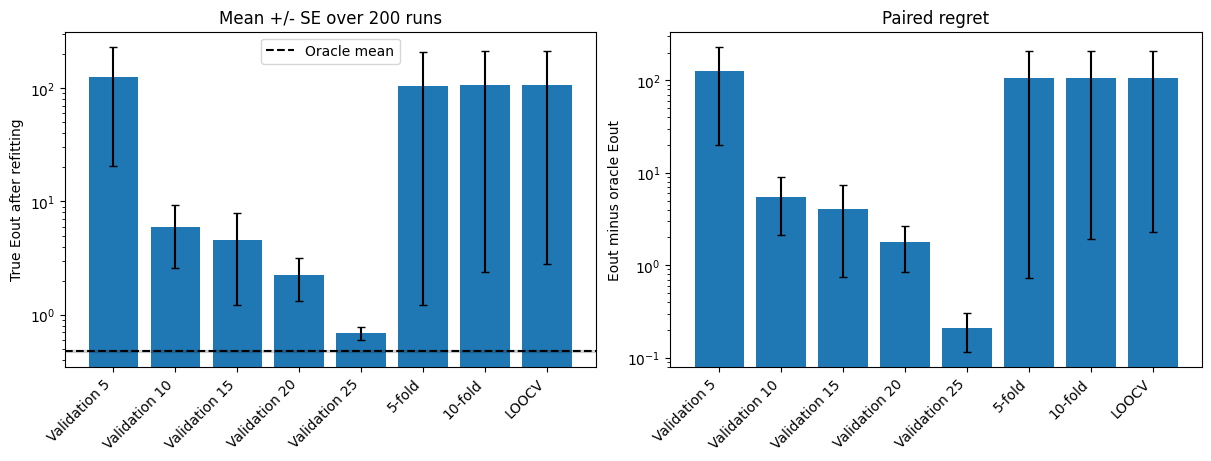

In [6]:
m, se = stat(eo)
mr, sr = stat(reg)
om, ose = stat(oracle)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
pos = np.arange(len(lbl))
axs[0].bar(pos, m, yerr=se, capsize=3)
axs[0].axhline(om, color="black", linestyle="--", label="Oracle mean")
axs[0].axhspan(om - ose, om + ose, color="black", alpha=0.12)
axs[0].set(ylabel="True Eout after refitting", title=f"Mean +/- SE over {R} runs")
axs[0].legend()
axs[1].bar(pos, mr, yerr=sr, capsize=3)
axs[1].set(ylabel="Eout minus oracle Eout", title="Paired regret")
for ax in axs:
    ax.set_yscale("log")
    ax.set_xticks(pos, lbl, rotation=45, ha="right")
plt.show()
print(f"Oracle: {om:.5g} +/- {ose:.3g} SE")
for j, lab in enumerate(lbl):
    print(f"{lab}: Eout={m[j]:.5g} +/- {se[j]:.3g} SE; "
          f"regret={mr[j]:.5g} +/- {sr[j]:.3g} SE")


K=5: true Eout - selected Eval = 122.48 +/- 117 SE
K=10: true Eout - selected Eval = 4.2562 +/- 2.2 SE
K=15: true Eout - selected Eval = 2.4564 +/- 1.82 SE
K=20: true Eout - selected Eval = 0.91437 +/- 0.422 SE
K=25: true Eout - selected Eval = 0.21122 +/- 0.112 SE


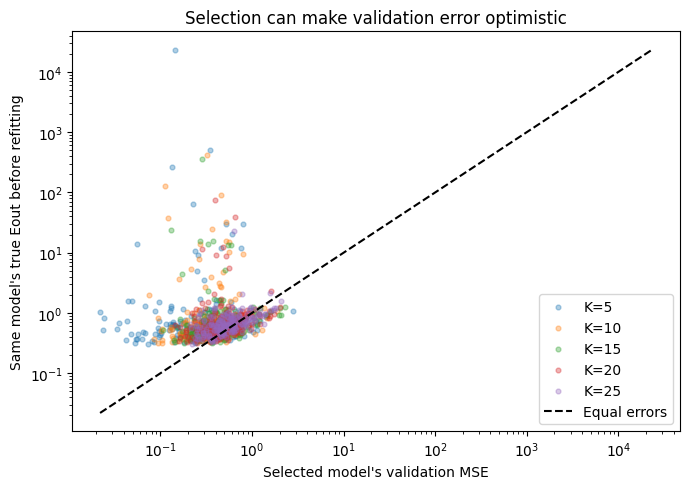

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for j, k in enumerate(ks):
    ax.scatter(ev[:, j], pre[:, j], s=12, alpha=0.35, label=f"K={k}")
    gap = pre[:, j] - ev[:, j]
    m, se = stat(gap)
    print(f"K={k}: true Eout - selected Eval = {m:.5g} +/- {se:.3g} SE")
lo = min(ev[:, :5].min(), pre.min())
hi = max(ev[:, :5].max(), pre.max())
ax.plot([lo, hi], [lo, hi], "k--", label="Equal errors")
ax.set(xscale="log", yscale="log", xlabel="Selected model's validation MSE",
       ylabel="Same model's true Eout before refitting", title="Selection can make validation error optimistic")
ax.legend()
fig.tight_layout()
plt.show()
